In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)
from scipy.cluster.hierarchy import dendrogram, linkage

sns.set_palette('colorblind')
RANDOM_STATE = 42

# ---------------- EDIT THESE FOR YOUR DATASET ----------------
DATA_PATH = '../../data/raw/gym_membership.csv'   # path to your CSV
DROP_COLS = []          # ID-like or useless columns, e.g. ['member_id']
LABEL_COL = None        # optional column used ONLY to validate clusters afterwards (e.g. 'membership_type'); else None
INCLUDE_CATEGORICAL = True   # one-hot encode low-cardinality text columns
CLIP_OUTLIERS = True         # clip extreme values using the IQR rule
# --------------------------------------------------------------

print("   ✅ Libraries imported, folders ready")

   ✅ Libraries imported, folders ready


In [2]:
print("\n" + "=" * 80)
print("CELL 2: DATASET LOADING AND AUDIT")
print("=" * 80)

df = pd.read_csv(DATA_PATH)

print(f"\n1️⃣ SHAPE: {df.shape[0]} rows x {df.shape[1]} columns")

print(f"\n2️⃣ COLUMN TYPES:")
print(df.dtypes.to_string())

print(f"\n3️⃣ MISSING VALUES:")
missing = df.isnull().sum()
print(missing[missing > 0].to_string() if missing.sum() > 0 else "   ✅ No missing values")

print(f"\n4️⃣ DUPLICATE ROWS: {df.duplicated().sum()}")

if LABEL_COL:
    print(f"\n5️⃣ VALIDATION LABEL DISTRIBUTION ({LABEL_COL}, not used for fitting):")
    print(df[LABEL_COL].value_counts().to_string())

print(f"\n6️⃣ FIRST ROWS:")
display(df.head())
print(f"\n7️⃣ SUMMARY STATISTICS:")
display(df.describe().round(2))


CELL 2: DATASET LOADING AND AUDIT

1️⃣ SHAPE: 1000 rows x 17 columns

2️⃣ COLUMN TYPES:
id                        int64
gender                   object
birthday                 object
Age                       int64
abonoment_type           object
visit_per_week            int64
days_per_week            object
attend_group_lesson        bool
fav_group_lesson         object
avg_time_check_in        object
avg_time_check_out       object
avg_time_in_gym           int64
drink_abo                  bool
fav_drink                object
personal_training          bool
name_personal_trainer    object
uses_sauna                 bool

3️⃣ MISSING VALUES:
fav_group_lesson         497
fav_drink                504
name_personal_trainer    482

4️⃣ DUPLICATE ROWS: 0

6️⃣ FIRST ROWS:


,id,gender,birthday,Age,abonoment_type,visit_per_week,days_per_week,attend_group_lesson,fav_group_lesson,avg_time_check_in,avg_time_check_out,avg_time_in_gym,drink_abo,fav_drink,personal_training,name_personal_trainer,uses_sauna
0,1,Female,1997-04-18,27,Premium,4,"Mon, Sat, Tue, Wed",True,"Kickboxen, BodyPump, Zumba",19:31:00,21:27:00,116,False,NaN,False,NaN,True
1,2,Female,1977-09-18,47,Standard,3,"Mon, Sat, Wed",False,NaN,19:31:00,20:19:00,48,False,NaN,True,Chantal,False
2,3,Male,1983-03-30,41,Premium,1,Sat,True,XCore,08:29:00,10:32:00,123,True,"berry_boost, lemon",True,Mike,False
3,4,Male,1980-04-12,44,Premium,3,"Sat, Tue, Wed",False,NaN,09:54:00,11:33:00,99,True,passion_fruit,True,Mike,True
4,5,Male,1980-09-10,44,Standard,2,"Thu, Wed",True,"Running, Yoga, Zumba",08:29:00,09:19:00,50,False,NaN,True,Mike,False



7️⃣ SUMMARY STATISTICS:


,id,Age,visit_per_week,avg_time_in_gym
count,1000.00,1000.00,1000.00,1000.00
mean,500.50,30.60,2.68,105.26
std,288.82,10.82,1.24,43.56
min,1.00,12.00,1.00,30.00
25%,250.75,21.00,2.00,67.00
50%,500.50,30.00,3.00,104.00
75%,750.25,40.00,3.00,143.00
max,1000.00,49.00,5.00,180.00



CELL 3: EXPLORATORY DATA ANALYSIS

1️⃣ DISTRIBUTIONS OF NUMERIC FEATURES...


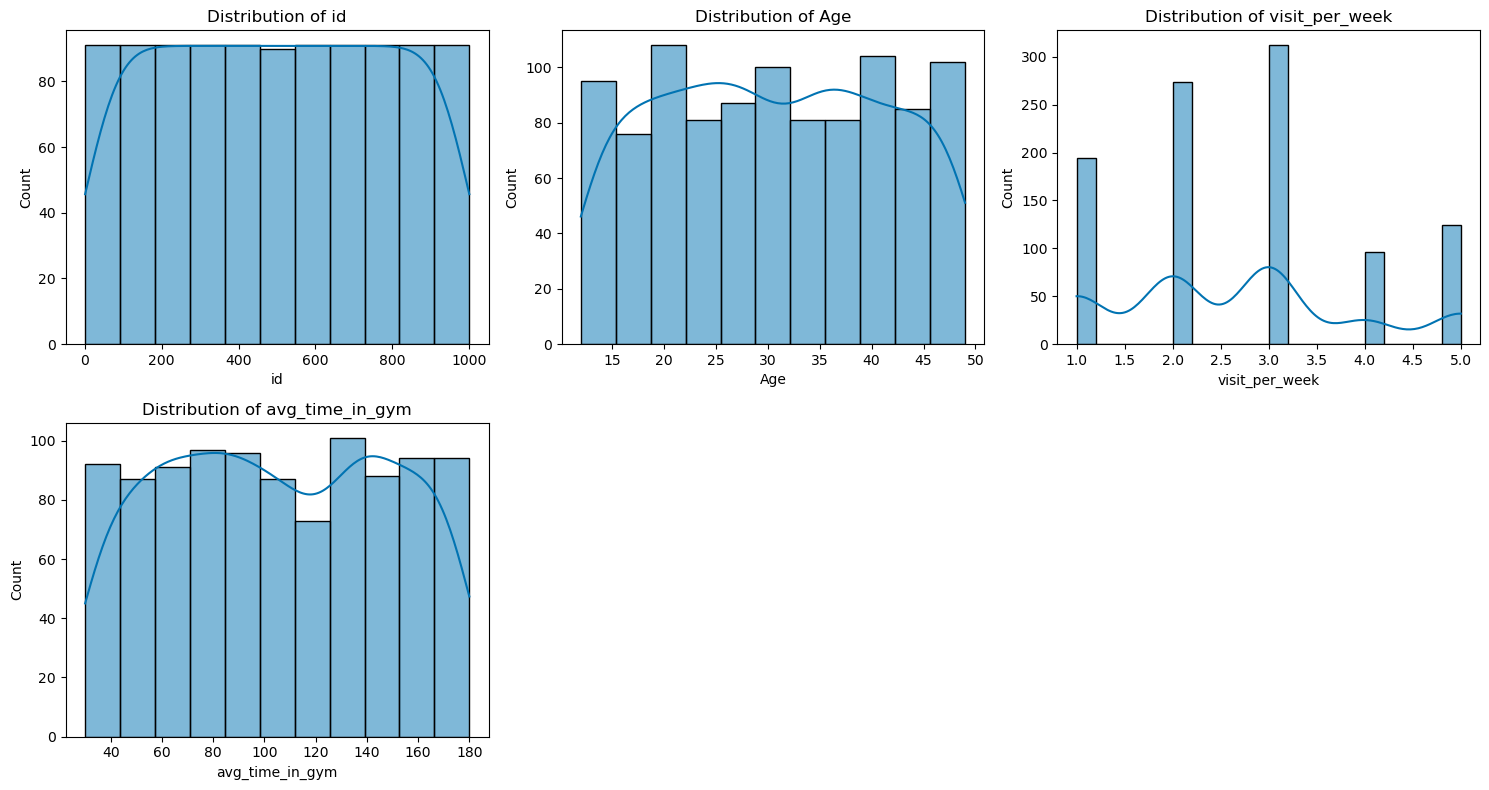


2️⃣ CORRELATION HEATMAP...


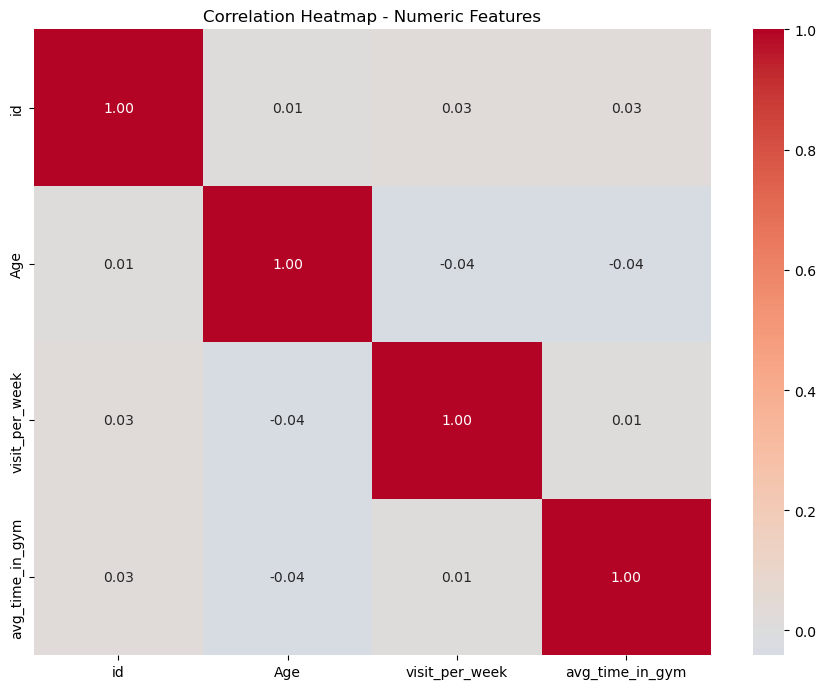


3️⃣ CATEGORICAL FEATURES...


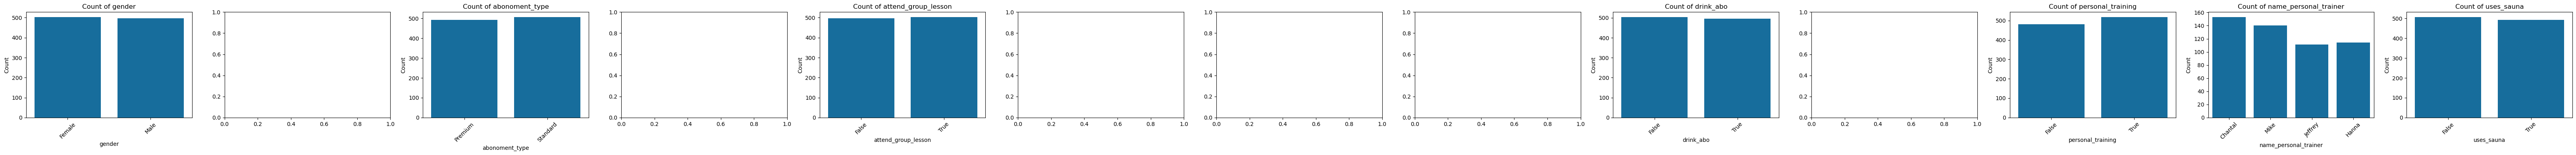


4️⃣ PAIRWISE SCATTER (first 4 numeric features)...


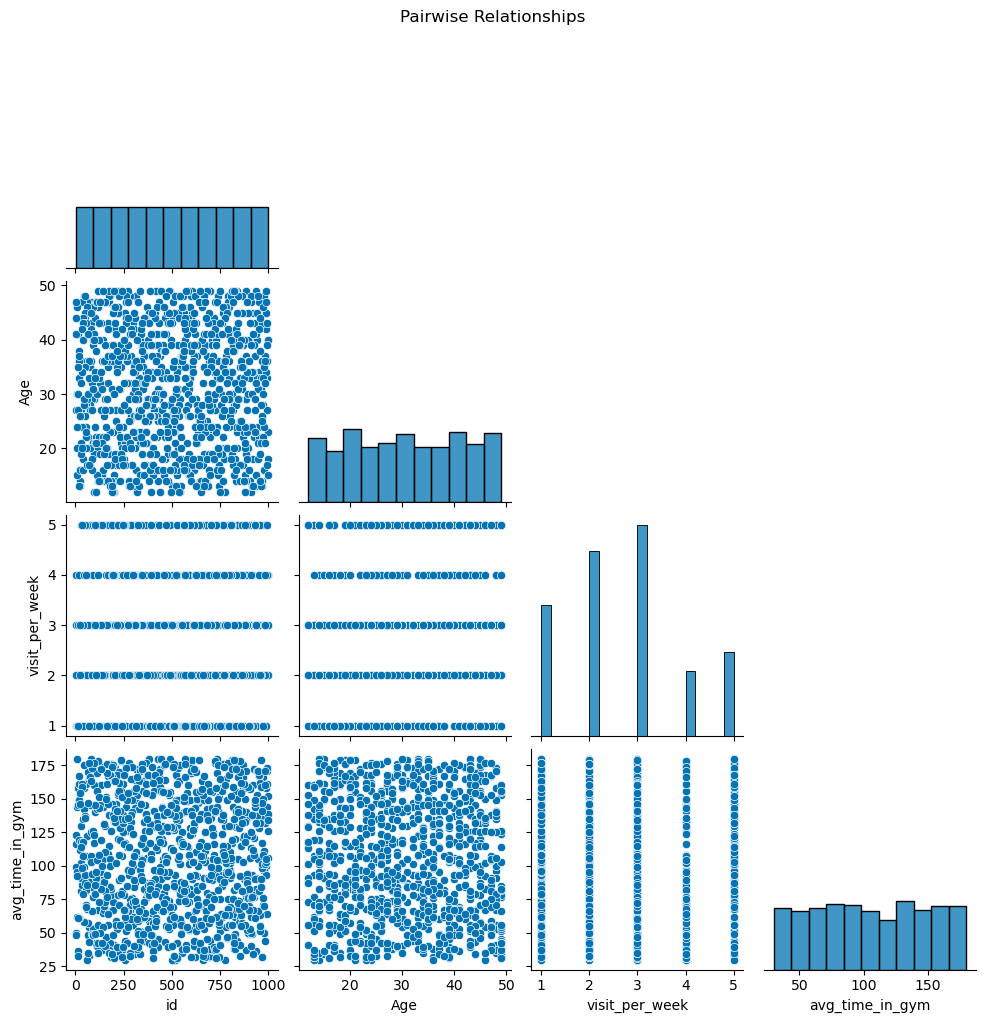

In [3]:
print("\n" + "=" * 80)
print("CELL 3: EXPLORATORY DATA ANALYSIS")
print("=" * 80)

num_cols = [c for c in df.select_dtypes(include=np.number).columns if c not in DROP_COLS]
cat_cols = [c for c in df.select_dtypes(exclude=np.number).columns if c not in DROP_COLS]

print(f"\n1️⃣ DISTRIBUTIONS OF NUMERIC FEATURES...")
n = len(num_cols)
ncols = 3
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = np.array(axes).reshape(-1)
for ax, col in zip(axes, num_cols):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(f'Distribution of {col}'); ax.set_xlabel(col); ax.set_ylabel('Count')
for ax in axes[n:]:
    ax.axis('off')
plt.tight_layout(); plt.show()

print(f"\n2️⃣ CORRELATION HEATMAP...")
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap - Numeric Features')
plt.tight_layout(); plt.show()

if cat_cols:
    print(f"\n3️⃣ CATEGORICAL FEATURES...")
    fig, axes = plt.subplots(1, len(cat_cols), figsize=(5 * len(cat_cols), 4))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, cat_cols):
        if df[col].nunique() <= 15:
            sns.countplot(data=df, x=col, ax=ax)
            ax.set_title(f'Count of {col}'); ax.set_xlabel(col); ax.set_ylabel('Count')
            ax.tick_params(axis='x', rotation=45)
    plt.tight_layout(); plt.show()

print(f"\n4️⃣ PAIRWISE SCATTER (first 4 numeric features)...")
sns.pairplot(df[num_cols[:4]].sample(min(len(df), 1000), random_state=RANDOM_STATE), corner=True)
plt.suptitle('Pairwise Relationships', y=1.02)
plt.show()

In [4]:
print("\n" + "=" * 80)
print("CELL 4: PREPROCESSING (CLEAN, ENCODE, SCALE)")
print("=" * 80)

# 1. Duplicates
print(f"\n1️⃣ REMOVING DUPLICATES...")
df_clean = df.drop_duplicates().reset_index(drop=True)
print(f"   ✅ {len(df) - len(df_clean)} duplicate rows removed")

# 2. Missing values
print(f"\n2️⃣ HANDLING MISSING VALUES...")
for c in df_clean.columns:
    if df_clean[c].isnull().any():
        if df_clean[c].dtype.kind in 'if':
            df_clean[c] = df_clean[c].fillna(df_clean[c].median())
        else:
            df_clean[c] = df_clean[c].fillna(df_clean[c].mode()[0])
print(f"   ✅ Missing values left: {df_clean.isnull().sum().sum()}")

# 3. Keep labels aside (never used for fitting)
y_true = df_clean[LABEL_COL].copy() if LABEL_COL else None
exclude = set(DROP_COLS) | ({LABEL_COL} if LABEL_COL else set())

# 4. Feature selection and encoding
print(f"\n3️⃣ BUILDING FEATURE MATRIX...")
num_features = [c for c in df_clean.select_dtypes(include=np.number).columns if c not in exclude]
X_features = df_clean[num_features].copy()

if INCLUDE_CATEGORICAL:
    cat_features = [c for c in df_clean.select_dtypes(exclude=np.number).columns
                    if c not in exclude and df_clean[c].nunique() <= 10]
    if cat_features:
        X_features = pd.concat([X_features, pd.get_dummies(df_clean[cat_features], drop_first=True).astype(int)], axis=1)
        print(f"   ✅ One-hot encoded: {cat_features}")

# 5. Outliers (IQR clipping)
print(f"\n4️⃣ OUTLIER CHECK (IQR rule)...")
outlier_report = {}
for c in num_features:
    q1, q3 = X_features[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_report[c] = int(((X_features[c] < lo) | (X_features[c] > hi)).sum())
    if CLIP_OUTLIERS:
        X_features[c] = X_features[c].clip(lo, hi)
print(pd.Series(outlier_report, name='outliers').to_string())
print(f"   ✅ Outliers {'clipped' if CLIP_OUTLIERS else 'reported only'}")

# 6. Scaling (no train/test split in clustering, so the scaler is fit on all rows)
print(f"\n5️⃣ SCALING (StandardScaler)...")
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X_features), columns=X_features.columns)
print(f"   ✅ Final feature matrix: {X_scaled.shape}")
print(f"   Features used: {list(X_scaled.columns)}")

X_scaled.to_csv('../../data/processed/X_clustering_scaled.csv', index=False)
joblib.dump(scaler, '../../models/clustering/scaler.pkl')


CELL 4: PREPROCESSING (CLEAN, ENCODE, SCALE)

1️⃣ REMOVING DUPLICATES...
   ✅ 0 duplicate rows removed

2️⃣ HANDLING MISSING VALUES...
   ✅ Missing values left: 0

3️⃣ BUILDING FEATURE MATRIX...
   ✅ One-hot encoded: ['gender', 'abonoment_type', 'attend_group_lesson', 'drink_abo', 'personal_training', 'name_personal_trainer', 'uses_sauna']

4️⃣ OUTLIER CHECK (IQR rule)...
id                   0
Age                  0
visit_per_week     124
avg_time_in_gym      0
   ✅ Outliers clipped

5️⃣ SCALING (StandardScaler)...
   ✅ Final feature matrix: (1000, 13)
   Features used: ['id', 'Age', 'visit_per_week', 'avg_time_in_gym', 'attend_group_lesson', 'drink_abo', 'personal_training', 'uses_sauna', 'gender_Male', 'abonoment_type_Standard', 'name_personal_trainer_Hanna', 'name_personal_trainer_Jeffrey', 'name_personal_trainer_Mike']


['../../models/clustering/scaler.pkl']


CELL 5: K-MEANS - CHOOSING k (ELBOW CURVE)

1️⃣ FITTING K-MEANS FOR k = 2 ... 10...


c:\Users\moule\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\moule\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\moule\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\moule\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\moule\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

,k,Inertia,Silhouette
0,2,11587.7170,0.1101
1,3,10546.9008,0.1425
2,4,9599.5259,0.1624
3,5,8780.1352,0.1446
4,6,8494.3919,0.1276
5,7,8159.3945,0.1329
6,8,7989.2333,0.1253
7,9,7821.9565,0.1202
8,10,7650.4711,0.1215


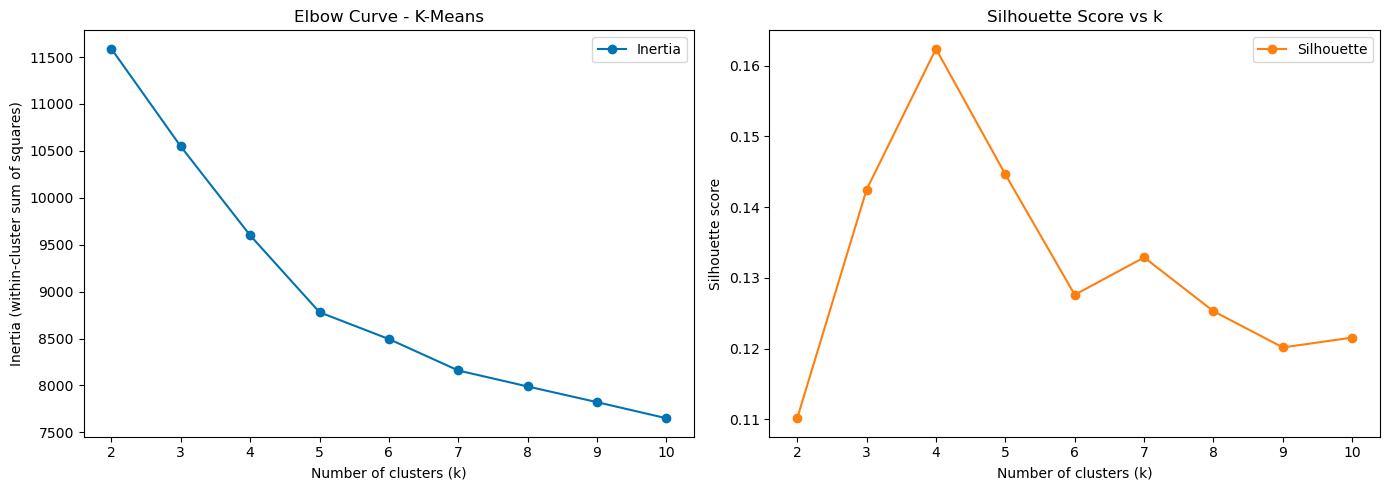


2️⃣ k with highest silhouette: 4
   ✅ Chosen k = 4


In [5]:
print("\n" + "=" * 80)
print("CELL 5: K-MEANS - CHOOSING k (ELBOW CURVE)")
print("=" * 80)

k_range = range(2, 11)
inertias, sil_scores = [], []

print(f"\n1️⃣ FITTING K-MEANS FOR k = 2 ... 10...")
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

scan_df = pd.DataFrame({'k': list(k_range), 'Inertia': inertias, 'Silhouette': sil_scores})
display(scan_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(list(k_range), inertias, marker='o', label='Inertia')
axes[0].set_title('Elbow Curve - K-Means'); axes[0].set_xlabel('Number of clusters (k)')
axes[0].set_ylabel('Inertia (within-cluster sum of squares)'); axes[0].legend()

axes[1].plot(list(k_range), sil_scores, marker='o', color='tab:orange', label='Silhouette')
axes[1].set_title('Silhouette Score vs k'); axes[1].set_xlabel('Number of clusters (k)')
axes[1].set_ylabel('Silhouette score'); axes[1].legend()
plt.tight_layout(); plt.show()

k_best_sil = int(scan_df.loc[scan_df['Silhouette'].idxmax(), 'k'])
print(f"\n2️⃣ k with highest silhouette: {k_best_sil}")

# Set k after reading BOTH plots. Default = best silhouette. Override if the elbow clearly suggests another k.
K_CHOSEN = k_best_sil
print(f"   ✅ Chosen k = {K_CHOSEN}")

In [6]:
print("\n" + "=" * 80)
print("CELL 6: K-MEANS CLUSTERING (Algorithm 1)")
print("=" * 80)

def cluster_metrics(X, labels):
    return (silhouette_score(X, labels),
            davies_bouldin_score(X, labels),
            calinski_harabasz_score(X, labels))

print(f"\n1️⃣ TRAINING K-MEANS (k={K_CHOSEN})...")
model_km = KMeans(n_clusters=K_CHOSEN, n_init=10, random_state=RANDOM_STATE)
labels_km = model_km.fit_predict(X_scaled)
print(f"   ✅ Model trained")

print(f"\n2️⃣ CLUSTER SIZES:")
print(pd.Series(labels_km).value_counts().sort_index().to_string())

print(f"\n3️⃣ CALCULATING METRICS...")
sil_km, db_km, ch_km = cluster_metrics(X_scaled, labels_km)
print(f"   ✅ Metrics calculated:")
print(f"      Silhouette (higher better): {sil_km:.4f}")
print(f"      Davies-Bouldin (lower better): {db_km:.4f}")
print(f"      Calinski-Harabasz (higher better): {ch_km:.2f}")

print(f"\n4️⃣ SAVING MODEL...")
joblib.dump(model_km, '../../models/clustering/kmeans.pkl')
print(f"   ✅ Model saved to models/clustering/kmeans.pkl")

clust_1 = {
    'Algorithm': 'K-Means',
    'Clusters': K_CHOSEN,
    'Silhouette': sil_km,
    'Davies_Bouldin': db_km,
    'Calinski_Harabasz': ch_km,
    'Hyperparameters': f'k={K_CHOSEN}, n_init=10'
}


CELL 6: K-MEANS CLUSTERING (Algorithm 1)

1️⃣ TRAINING K-MEANS (k=4)...
   ✅ Model trained

2️⃣ CLUSTER SIZES:
0    482
1    264
2    140
3    114

3️⃣ CALCULATING METRICS...
   ✅ Metrics calculated:
      Silhouette (higher better): 0.1624
      Davies-Bouldin (lower better): 2.2515
      Calinski-Harabasz (higher better): 117.61

4️⃣ SAVING MODEL...
   ✅ Model saved to models/clustering/kmeans.pkl


c:\Users\moule\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(



CELL 7: HIERARCHICAL CLUSTERING - DENDROGRAM

1️⃣ COMPUTING LINKAGE MATRIX (Ward)...

2️⃣ PLOTTING DENDROGRAM (last 30 merges shown)...


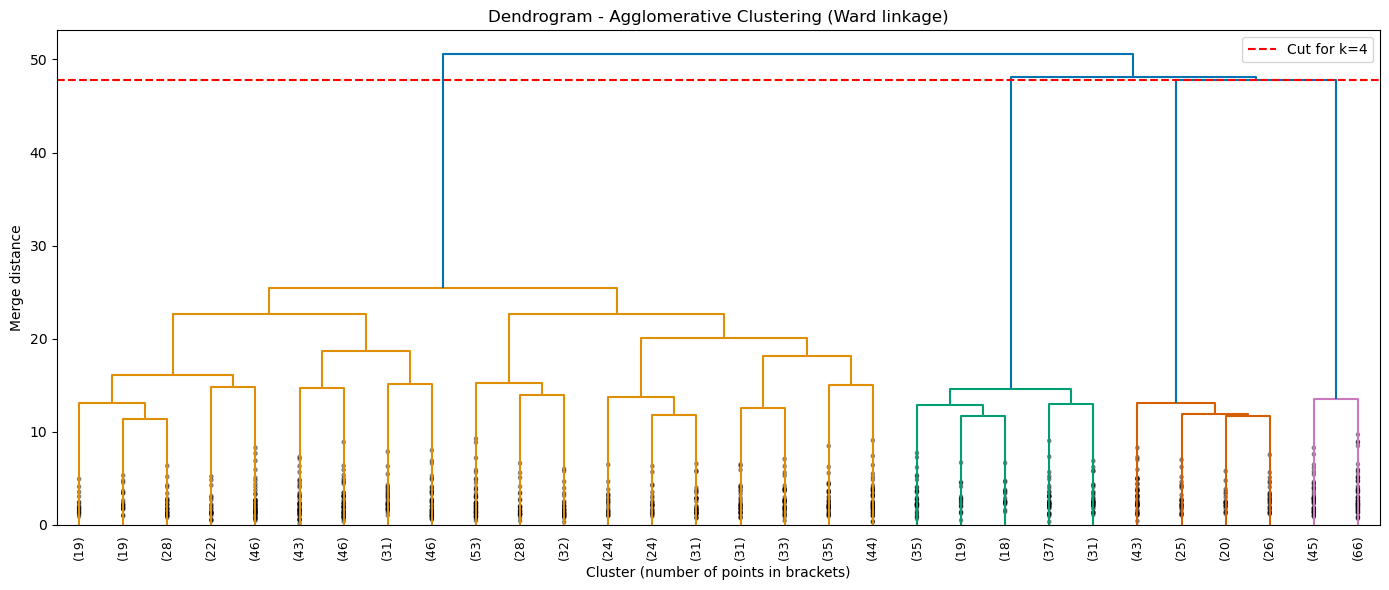

   ✅ Dendrogram plotted (a long vertical gap suggests a natural number of clusters)


In [7]:
print("\n" + "=" * 80)
print("CELL 7: HIERARCHICAL CLUSTERING - DENDROGRAM")
print("=" * 80)

print(f"\n1️⃣ COMPUTING LINKAGE MATRIX (Ward)...")
Z = linkage(X_scaled, method='ward')

print(f"\n2️⃣ PLOTTING DENDROGRAM (last 30 merges shown)...")
plt.figure(figsize=(14, 6))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90, leaf_font_size=9, show_contracted=True)
plt.title('Dendrogram - Agglomerative Clustering (Ward linkage)')
plt.xlabel('Cluster (number of points in brackets)')
plt.ylabel('Merge distance')
cut_height = Z[-K_CHOSEN + 1, 2]
plt.axhline(y=cut_height, color='red', linestyle='--', label=f'Cut for k={K_CHOSEN}')
plt.legend()
plt.tight_layout(); plt.show()
print(f"   ✅ Dendrogram plotted (a long vertical gap suggests a natural number of clusters)")

In [8]:
print("\n" + "=" * 80)
print("CELL 8: AGGLOMERATIVE - COMPARING LINKAGE STRATEGIES")
print("=" * 80)

linkage_rows = []
for method in ['ward', 'complete', 'average', 'single']:
    agg = AgglomerativeClustering(n_clusters=K_CHOSEN, linkage=method)
    lab = agg.fit_predict(X_scaled)
    if len(set(lab)) < 2:
        continue
    s, d, c = cluster_metrics(X_scaled, lab)
    linkage_rows.append({'Linkage': method, 'Silhouette': s, 'Davies_Bouldin': d,
                         'Calinski_Harabasz': c, 'Smallest_Cluster_Size': pd.Series(lab).value_counts().min()})

linkage_df = pd.DataFrame(linkage_rows).sort_values('Silhouette', ascending=False).reset_index(drop=True)
display(linkage_df.round(4))

best_linkage = linkage_df.iloc[0]['Linkage']
print(f"\n   ✅ Best linkage by silhouette: {best_linkage}")
print(f"   Note: single linkage often produces one huge cluster and tiny ones (chaining effect)")


CELL 8: AGGLOMERATIVE - COMPARING LINKAGE STRATEGIES


,Linkage,Silhouette,Davies_Bouldin,Calinski_Harabasz,Smallest_Cluster_Size
0,ward,0.2129,1.7875,126.1172,111
1,single,0.2129,1.7875,126.1172,111
2,average,0.2114,1.7986,125.5998,111
3,complete,0.2096,1.7965,123.4194,111



   ✅ Best linkage by silhouette: ward
   Note: single linkage often produces one huge cluster and tiny ones (chaining effect)


In [10]:
print("\n" + "=" * 80)
print("CELL 9: AGGLOMERATIVE HIERARCHICAL CLUSTERING (Algorithm 2)")
print("=" * 80)
import os

print(f"\n1️⃣ TRAINING AGGLOMERATIVE (k={K_CHOSEN}, linkage={best_linkage})...")
model_agg = AgglomerativeClustering(n_clusters=K_CHOSEN, linkage=best_linkage)
labels_agg = model_agg.fit_predict(X_scaled)
print(f"   ✅ Model fitted")

print(f"\n2️⃣ CLUSTER SIZES:")
print(pd.Series(labels_agg).value_counts().sort_index().to_string())

print(f"\n3️⃣ CALCULATING METRICS...")
sil_agg, db_agg, ch_agg = cluster_metrics(X_scaled, labels_agg)
print(f"   ✅ Metrics calculated:")
print(f"      Silhouette (higher better): {sil_agg:.4f}")
print(f"      Davies-Bouldin (lower better): {db_agg:.4f}")
print(f"      Calinski-Harabasz (higher better): {ch_agg:.2f}")

# Agglomerative has no predict(), so save the labels instead of a model
pd.DataFrame({'agglomerative_label': labels_agg}).to_csv('../../results/clustering/agglomerative_labels.csv', index=False)
print(f"   ✅ Labels saved to results/clustering/agglomerative_labels.csv")

clust_2 = {
    'Algorithm': 'Agglomerative Hierarchical',
    'Clusters': K_CHOSEN,
    'Silhouette': sil_agg,
    'Davies_Bouldin': db_agg,
    'Calinski_Harabasz': ch_agg,
    'Hyperparameters': f'k={K_CHOSEN}, linkage={best_linkage}'
}


CELL 9: AGGLOMERATIVE HIERARCHICAL CLUSTERING (Algorithm 2)

1️⃣ TRAINING AGGLOMERATIVE (k=4, linkage=ward)...
   ✅ Model fitted

2️⃣ CLUSTER SIZES:
0    635
1    111
2    140
3    114

3️⃣ CALCULATING METRICS...
   ✅ Metrics calculated:
      Silhouette (higher better): 0.2129
      Davies-Bouldin (lower better): 1.7875
      Calinski-Harabasz (higher better): 126.12
   ✅ Labels saved to results/clustering/agglomerative_labels.csv



CELL 10: COMPARISON - ALL CLUSTERING ALGORITHMS


,Algorithm,Clusters,Silhouette,Davies_Bouldin,Calinski_Harabasz,Hyperparameters
0,K-Means,4,0.1624,2.2515,117.6055,"k=4, n_init=10"
1,Agglomerative Hierarchical,4,0.2129,1.7875,126.1172,"k=4, linkage=ward"



How to read it: Silhouette higher = better | Davies-Bouldin lower = better | Calinski-Harabasz higher = better

Best per metric: {'Silhouette': 'Agglomerative Hierarchical', 'Davies_Bouldin': 'Agglomerative Hierarchical', 'Calinski_Harabasz': 'Agglomerative Hierarchical'}


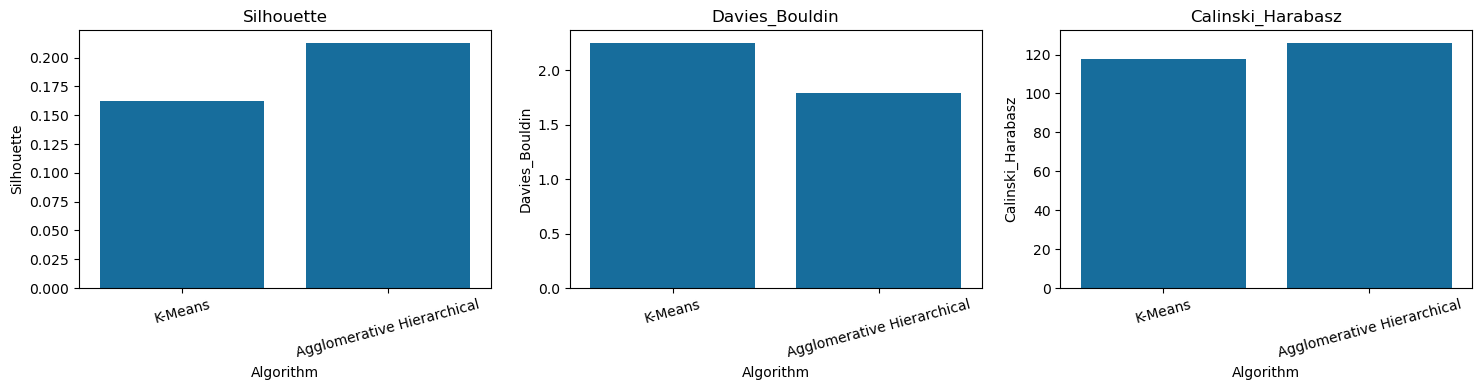

In [11]:
print("\n" + "=" * 80)
print("CELL 10: COMPARISON - ALL CLUSTERING ALGORITHMS")
print("=" * 80)

cluster_results = pd.DataFrame([clust_1, clust_2])
cluster_results.to_csv('../../results/clustering/Master_Clustering_Results.csv', index=False)
display(cluster_results.round(4))

print(f"\nHow to read it: Silhouette higher = better | Davies-Bouldin lower = better | Calinski-Harabasz higher = better")

wins = {
    'Silhouette': cluster_results.loc[cluster_results['Silhouette'].idxmax(), 'Algorithm'],
    'Davies_Bouldin': cluster_results.loc[cluster_results['Davies_Bouldin'].idxmin(), 'Algorithm'],
    'Calinski_Harabasz': cluster_results.loc[cluster_results['Calinski_Harabasz'].idxmax(), 'Algorithm'],
}
print(f"\nBest per metric: {wins}")

metrics_plot = ['Silhouette', 'Davies_Bouldin', 'Calinski_Harabasz']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, m in zip(axes, metrics_plot):
    sns.barplot(data=cluster_results, x='Algorithm', y=m, ax=ax)
    ax.set_title(m); ax.set_xlabel('Algorithm'); ax.set_ylabel(m)
    ax.tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.show()


CELL 11: PCA 2D CLUSTER VISUALISATION

   Explained variance: PC1 = 12.2%, PC2 = 9.5%, total = 21.7%


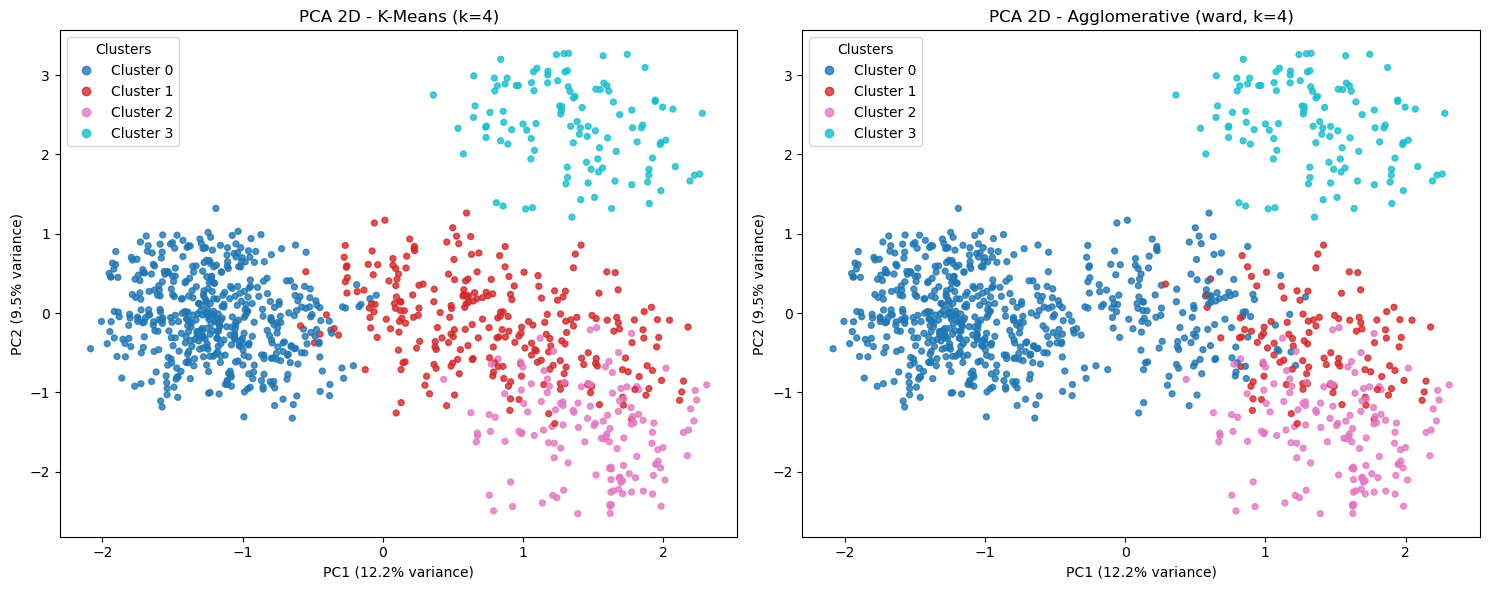

   ✅ PCA plots complete


In [12]:
print("\n" + "=" * 80)
print("CELL 11: PCA 2D CLUSTER VISUALISATION")
print("=" * 80)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
ev = pca.explained_variance_ratio_
print(f"\n   Explained variance: PC1 = {ev[0]*100:.1f}%, PC2 = {ev[1]*100:.1f}%, total = {ev.sum()*100:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, lab, title in zip(axes, [labels_km, labels_agg],
                          [f'K-Means (k={K_CHOSEN})', f'Agglomerative ({best_linkage}, k={K_CHOSEN})']):
    sc = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=lab, cmap='tab10', s=18, alpha=0.8)
    ax.set_title(f'PCA 2D - {title}')
    ax.set_xlabel(f'PC1 ({ev[0]*100:.1f}% variance)'); ax.set_ylabel(f'PC2 ({ev[1]*100:.1f}% variance)')
    handles, _ = sc.legend_elements()
    ax.legend(handles, [f'Cluster {i}' for i in sorted(set(lab))], title='Clusters', loc='best')
plt.tight_layout(); plt.show()
print(f"   ✅ PCA plots complete")


CELL 12: t-SNE CLUSTER VISUALISATION

1️⃣ RUNNING t-SNE (may take a minute)...
   ✅ t-SNE done


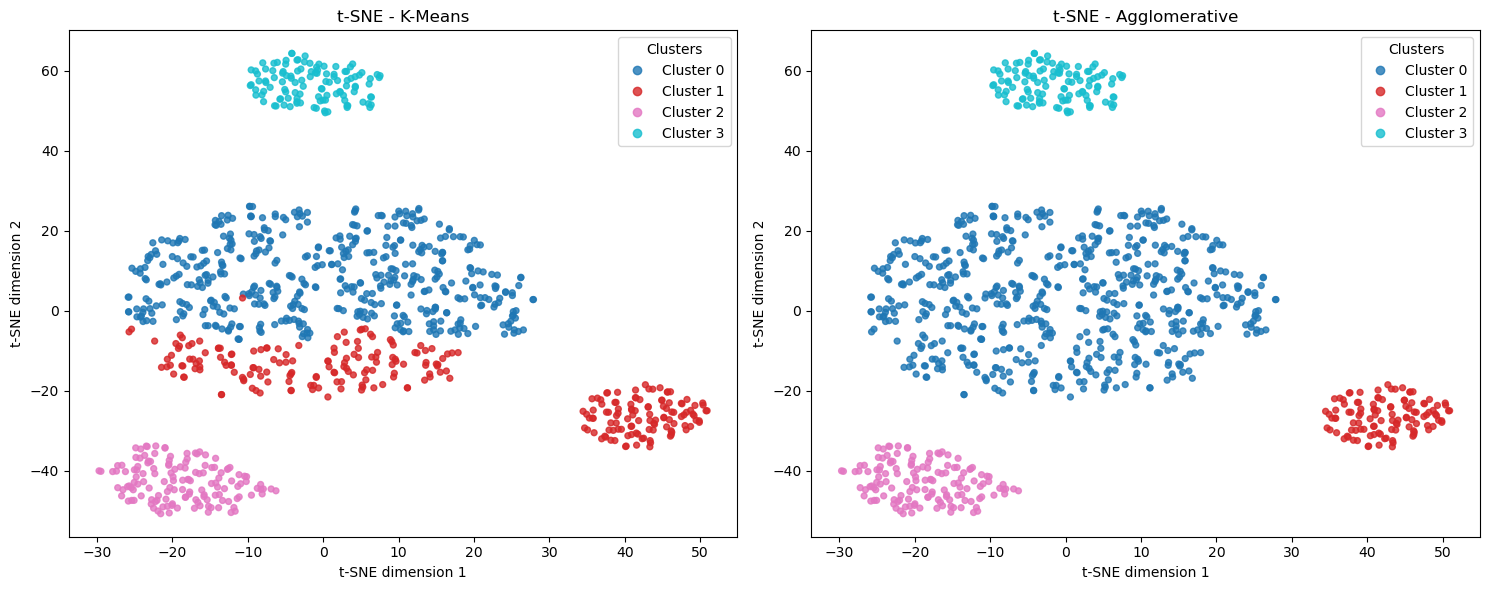

   Note: do not read cluster sizes or gaps between clusters in t-SNE as meaningful


In [13]:
print("\n" + "=" * 80)
print("CELL 12: t-SNE CLUSTER VISUALISATION")
print("=" * 80)

print(f"\n1️⃣ RUNNING t-SNE (may take a minute)...")
tsne = TSNE(n_components=2, perplexity=30, init='pca', random_state=RANDOM_STATE)
X_tsne = tsne.fit_transform(X_scaled)
print(f"   ✅ t-SNE done")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, lab, title in zip(axes, [labels_km, labels_agg], ['K-Means', 'Agglomerative']):
    sc = ax.scatter(X_tsne[:, 0], X_tsne[:, 1], c=lab, cmap='tab10', s=18, alpha=0.8)
    ax.set_title(f't-SNE - {title}'); ax.set_xlabel('t-SNE dimension 1'); ax.set_ylabel('t-SNE dimension 2')
    handles, _ = sc.legend_elements()
    ax.legend(handles, [f'Cluster {i}' for i in sorted(set(lab))], title='Clusters', loc='best')
plt.tight_layout(); plt.show()
print(f"   Note: do not read cluster sizes or gaps between clusters in t-SNE as meaningful")


CELL 13: CLUSTER PROFILING (K-MEANS)

1️⃣ MEMBERS PER CLUSTER:
         Count  Percent
Cluster                
0          482     48.2
1          264     26.4
2          140     14.0
3          114     11.4

2️⃣ AVERAGE FEATURE VALUES PER CLUSTER (original units):


,id,Age,visit_per_week,avg_time_in_gym
Cluster,,,,
0,503.78,29.27,2.66,104.34
1,476.73,32.09,2.62,105.07
2,511.25,31.77,2.60,105.91
3,528.46,31.37,2.46,108.80



3️⃣ HEATMAP OF STANDARDISED MEANS (what makes each cluster different)...


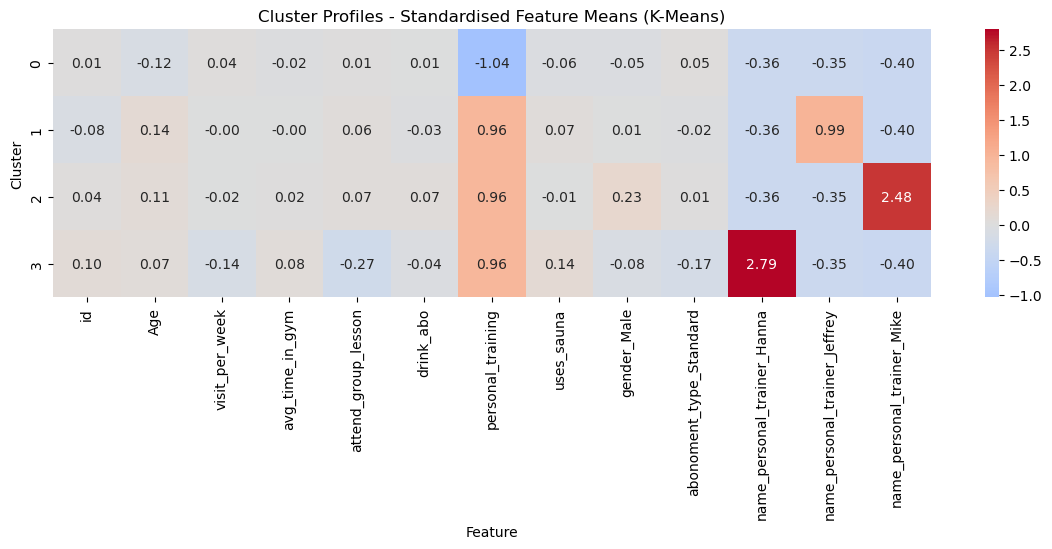

In [14]:
print("\n" + "=" * 80)
print("CELL 13: CLUSTER PROFILING (K-MEANS)")
print("=" * 80)

profile_df = X_features.copy()
profile_df['Cluster'] = labels_km

print(f"\n1️⃣ MEMBERS PER CLUSTER:")
sizes = profile_df['Cluster'].value_counts().sort_index()
print(pd.DataFrame({'Count': sizes, 'Percent': (sizes / len(profile_df) * 100).round(1)}).to_string())

print(f"\n2️⃣ AVERAGE FEATURE VALUES PER CLUSTER (original units):")
cluster_means = profile_df.groupby('Cluster')[num_features].mean().round(2)
display(cluster_means)

print(f"\n3️⃣ HEATMAP OF STANDARDISED MEANS (what makes each cluster different)...")
z_means = X_scaled.copy()
z_means['Cluster'] = labels_km
z_means = z_means.groupby('Cluster').mean()
plt.figure(figsize=(max(8, len(z_means.columns) * 0.9), 4 + K_CHOSEN * 0.4))
sns.heatmap(z_means, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Cluster Profiles - Standardised Feature Means (K-Means)')
plt.xlabel('Feature'); plt.ylabel('Cluster')
plt.tight_layout(); plt.show()

cluster_means.to_csv('../../results/clustering/kmeans_cluster_profiles.csv')